# Feature analysis of the final LightGBM models

This notebook interprets the final LightGBM models for the split named by `SPLIT_SCHEME`. The models were refitted on train + validation data in `model_development.ipynb` and are only loaded here; nothing is retrained.

Five models are analysed in one run:
- `L`, `H` and `All`: the Low-MP, High-MP and All-data models trained on the full training set (`full` run).
- `L_undersampled`: the Low-MP model of the `balanced` run, trained (and finally refit) on Low-MP training and validation compounds undersampled to the High-MP counts, i.e. on as many compounds as the High-MP model. It is used only to check whether the Low-MP feature ranking depends on the training-set size.
- `All_balanced`: the All-data model of the `balanced` run (BAL-MP), trained on the balanced training and validation lists (undersampled Low-MP plus all High-MP compounds, 50:50). It is used only in the second representation-block figure.

SHAP values are computed on the test set: Low-MP test compounds for `L` and `L_undersampled`, High-MP test compounds for `H`, and all test compounds for `All` and `All_balanced`. At most `MAX_SHAP_ROWS` rows are used per subset, sampled reproducibly.

**Figures**
- Main: importance by representation block (Low-, High- and All-MP models; and full versus balanced-run models); SHAP beeswarm of the Low- and High-MP models; mirrored top-10 SHAP features, Low versus High; Low- versus High-MP values of the top features.
- Supplementary: SHAP beeswarm of the All-data model; gain importance of the three models; SHAP rank heatmap and mirrored top-10 SHAP features of the full versus undersampled Low-MP models.

Tables are written to `outputs/<SPLIT_SCHEME>/tables/`. Figures are only displayed: each figure cell has a commented `fig.savefig(...)` line, and uncommenting it saves that figure to `outputs/<SPLIT_SCHEME>/figures/`.

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / '0_data' / 'outputs' / 'combined_data.parquet').is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / '0_data' / 'outputs' / 'combined_data.parquet').is_file():
    raise FileNotFoundError('Run this notebook from the repository root or a project subdirectory.')

SPLIT_SCHEME = 'stereo_cleaned'  # folder written by 1_data_split/data_split.ipynb
MODEL_TYPE = 'LGB'
FINAL_FIT_MODE = 'train_plus_validation'
MP_COLUMN = 'MP'
CLASS_COLUMN = 'MP_class'
RANDOM_STATE = 2026
TOP_N = 20
MAX_SHAP_ROWS = 5000
FIGURE_DPI = 300
# Feature-name prefixes of the representation blocks, as in feature_engineering.ipynb.
REPRESENTATION_PREFIXES = {
    'rdkit2d': 'rdkit2d_',
    'maccs': 'maccs_',
    'ecfp4_bit': 'ecfp4_bit_',
    'chemberta2_mtr': 'chemberta2_mtr_',
    'graph_emb': 'graph_emb_',
}
BINARY_PREFIXES = ('maccs_', 'ecfp4_bit_')

# Model key -> model run folder, regime, training variant recorded in the model metadata,
# and the test subset used for SHAP.
MODEL_SPECS = {
    'L': {'run': 'full', 'regime': 'L', 'test_subset': 'low'},
    'H': {'run': 'full', 'regime': 'H', 'test_subset': 'high'},
    'All': {'run': 'full', 'regime': 'All', 'test_subset': 'all'},
    'L_undersampled': {'run': 'balanced', 'regime': 'L', 'test_subset': 'low'},
    'All_balanced': {'run': 'balanced', 'regime': 'All', 'test_subset': 'all'},
}
MODEL_LABELS = {
    'L': 'Low-MP model',
    'H': 'High-MP model',
    'All': 'All-MP model',
    'L_undersampled': 'Low-MP (US) model',
    'All_balanced': 'BAL-MP model',
}
MODEL_COLORS = {'L': '#477C9B', 'H': '#CA806B', 'All': '#83A891', 'L_undersampled': '#7776B3',
                'All_balanced': '#4C9291'}  # as in 4_model_evaluation
SHARED_COLOR = '#555555'
LOW_BOX_COLOR, HIGH_BOX_COLOR = MODEL_COLORS['L'], MODEL_COLORS['H']

FEATURE_ROOT = PROJECT_ROOT / '2_feature_engineering' / 'outputs' / SPLIT_SCHEME
FEATURE_DIR = FEATURE_ROOT / 'selected_features'
FEATURE_LIST_PATH = FEATURE_ROOT / 'selected_features.csv'
TRAIN_PATH = FEATURE_DIR / 'train_selected_features.parquet'
TEST_PATH = FEATURE_DIR / 'test_selected_features.parquet'
BALANCED_TRAIN_LIST_PATH = PROJECT_ROOT / '1_data_split' / 'outputs' / SPLIT_SCHEME / 'balanced_train.csv'
BALANCED_VALIDATION_LIST_PATH = PROJECT_ROOT / '1_data_split' / 'outputs' / SPLIT_SCHEME / 'balanced_validation.csv'
MODEL_ROOT = PROJECT_ROOT / '3_model_development' / 'models' / SPLIT_SCHEME
OUTPUT_DIR = PROJECT_ROOT / '5_feature_analysis' / 'outputs' / SPLIT_SCHEME
TABLE_DIR = OUTPUT_DIR / 'tables'
FIGURE_DIR = OUTPUT_DIR / 'figures'
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print('Split scheme:', SPLIT_SCHEME)
print('Model runs:', {key: spec['run'] for key, spec in MODEL_SPECS.items()})
print('Table directory:', TABLE_DIR.relative_to(PROJECT_ROOT))
print('Figure directory:', FIGURE_DIR.relative_to(PROJECT_ROOT))

Split scheme: stereo_cleaned
Model runs: {'L': 'full', 'H': 'full', 'All': 'full', 'L_undersampled': 'balanced', 'All_balanced': 'balanced'}
Table directory: 5_feature_analysis/outputs/stereo_cleaned/tables
Figure directory: 5_feature_analysis/outputs/stereo_cleaned/figures


## Load the final models and the test features

All four models use the same selected features and the same test table. Each model's metadata must match the split scheme, training variant and feature count, and its feature order must match the feature list. The `L_undersampled` and `All_balanced` models must have been trained and refit on exactly the balanced training and validation lists (`1_data_split/outputs/<SPLIT_SCHEME>/balanced_train.csv` and `balanced_validation.csv`), in which Low-MP compounds are undersampled to the High-MP count.

The `L` and `L_undersampled` models are explained on the same Low-MP test sample, so their SHAP values are directly comparable.

In [2]:
if not FEATURE_LIST_PATH.is_file():
    raise FileNotFoundError(f'Missing feature list: {FEATURE_LIST_PATH}')
feature_names = pd.read_csv(FEATURE_LIST_PATH)['Feature'].dropna().astype(str).tolist()
test_data = pd.read_parquet(TEST_PATH)
missing = sorted(set(feature_names).difference(test_data.columns))
if missing:
    raise ValueError(f'Test table is missing selected features: {missing[:10]}')
if test_data[feature_names].isna().any().any():
    raise ValueError('Test table contains NaN values in selected features.')
def load_final_model(model_dir, regime, expected_training_variant):
    stem = f'{MODEL_TYPE}_{regime}_{FINAL_FIT_MODE}'
    model_path = model_dir / f'best_model_{stem}.joblib'
    metadata_path = model_dir / f'model_metadata_{stem}.json'
    for path in [model_path, metadata_path]:
        if not path.is_file():
            raise FileNotFoundError(f'Missing saved final model file: {path}')
    metadata = json.loads(metadata_path.read_text())
    expected = {'split_scheme': SPLIT_SCHEME, 'training_variant': expected_training_variant,
                'selected_feature_count': len(feature_names), 'test_used': False}
    mismatched = {key: metadata.get(key) for key, value in expected.items() if metadata.get(key) != value}
    if mismatched:
        raise ValueError(f'{model_path.name} metadata does not match this analysis: {mismatched}')
    model = joblib.load(model_path)
    if model.booster_.feature_name() != feature_names:
        raise ValueError(f'{model_path.name} was trained on a different feature order.')
    return model, metadata

models, model_metadata = {}, {}
for key, spec in MODEL_SPECS.items():
    models[key], model_metadata[key] = load_final_model(MODEL_ROOT / spec['run'], spec['regime'], spec['run'])

def normalized_class(frame):
    return frame[CLASS_COLUMN].astype(str).str.strip().str.lower().replace({'l': 'low', 'h': 'high'})

# The balanced-run models are tuned and refit on the balanced training and validation lists:
# the undersampled Low-MP model on their Low-MP compounds, the BAL-MP model on all of them.
for split_name, list_path, rows_key in [('training', BALANCED_TRAIN_LIST_PATH, 'train_rows_used'),
                                        ('validation', BALANCED_VALIDATION_LIST_PATH, 'validation_rows_used')]:
    balanced_counts = normalized_class(pd.read_csv(list_path, usecols=[CLASS_COLUMN])).value_counts()
    if not balanced_counts['low'] == balanced_counts['high'] == model_metadata['L_undersampled'][rows_key]:
        raise ValueError(f'L_undersampled {split_name} rows do not match the balanced Low-MP rows: {balanced_counts.to_dict()}')
    if model_metadata['All_balanced'][rows_key] != int(balanced_counts.sum()):
        raise ValueError(f'All_balanced {split_name} rows do not match the balanced {split_name} list: {balanced_counts.to_dict()}')

test_labels = normalized_class(test_data)
subset_masks = {'low': test_labels == 'low', 'high': test_labels == 'high', 'all': pd.Series(True, index=test_data.index)}

# One reproducible SHAP sample per test subset, shared by the models that use that subset.
shap_samples = {}
for subset_name, mask in subset_masks.items():
    subset = test_data.loc[mask, feature_names]
    if len(subset) > MAX_SHAP_ROWS:
        subset = subset.sample(MAX_SHAP_ROWS, random_state=RANDOM_STATE)
    shap_samples[subset_name] = subset

print('Test rows:', len(test_data))
print('Feature count:', len(feature_names))
print('SHAP rows per test subset:', {name: len(frame) for name, frame in shap_samples.items()})
display(pd.DataFrame({
    key: {'Model run': spec['run'], 'Regime': spec['regime'], 'SHAP test subset': spec['test_subset'],
          'Train rows used': model_metadata[key]['train_rows_used'],
          'Validation rows used': model_metadata[key]['validation_rows_used'],
          'Final-fit rows': model_metadata[key]['final_fit_rows']}
    for key, spec in MODEL_SPECS.items()
}).T)

Test rows: 55427
Feature count: 1690
SHAP rows per test subset: {'low': 5000, 'high': 4282, 'all': 5000}


,Model run,Regime,SHAP test subset,Train rows used,Validation rows used,Final-fit rows
L,full,L,low,153434,51145,204579
H,full,H,high,12846,4282,17128
All,full,All,all,166280,55427,221707
L_undersampled,balanced,L,low,12846,4282,17128
All_balanced,balanced,All,all,25692,8564,34256


## Built-in LightGBM importance

Gain importance is the total loss reduction from splits on a feature, and split importance counts those splits. Raw gain grows with the number of training rows, so models are compared only through `Gain_percent`, the share of that model's total gain.

In [3]:
importance_tables = {}
for key, model in models.items():
    booster = model.booster_
    importance = pd.DataFrame({
        'Feature': booster.feature_name(),
        'Split_importance': booster.feature_importance(importance_type='split'),
        'Gain_importance': booster.feature_importance(importance_type='gain'),
    })
    importance['Split_percent'] = 100 * importance['Split_importance'] / max(1, importance['Split_importance'].sum())
    importance['Gain_percent'] = 100 * importance['Gain_importance'] / max(1e-12, importance['Gain_importance'].sum())
    importance = importance.sort_values('Gain_importance', ascending=False).reset_index(drop=True)
    importance.insert(0, 'Gain_rank', np.arange(1, len(importance) + 1))
    importance_tables[key] = importance
    importance.to_csv(TABLE_DIR / f'gain_importance_{key}.csv', index=False)

display(pd.concat(
    {MODEL_LABELS[key]: table.head(10).set_index('Gain_rank')[['Feature', 'Gain_percent']] for key, table in importance_tables.items()},
    axis=1,
).round(2))

Low-MP model                           High-MP model  \
                             Feature Gain_percent                    Feature   
Gain_rank                                                                      
1                 rdkit2d_NumHDonors         4.74       rdkit2d_FractionCSP3   
2                       rdkit2d_TPSA         4.09              graph_emb_188   
3                    rdkit2d_BertzCT         3.31              graph_emb_305   
4                      graph_emb_078         3.10             ecfp4_bit_1745   
5                      graph_emb_484         3.10   rdkit2d_FpDensityMorgan3   
6          rdkit2d_NumRotatableBonds         2.71  rdkit2d_NumRotatableBonds   
7                      graph_emb_159         2.69           rdkit2d_fr_Ar_NH   
8                      graph_emb_429         1.42        chemberta2_mtr_0145   
9                          maccs_155         1.37              graph_emb_031   
10                         maccs_131         1.28              graph_emb_466   

                                     All-MP model               \
          Gain_percent                    Feature Gain_percent   
Gain_rank                                                        
1                 1.67              graph_emb_484         7.60   
2                 1.66         rdkit2d_NumHDonors         6.53   
3                 1.03               rdkit2d_TPSA         3.91   
4                 1.01                  maccs_101         3.64   
5                 0.85  rdkit2d_NumRotatableBonds         3.30   
6                 0.73              graph_emb_159         2.72   
7                 0.70              graph_emb_078         2.11   
8                 0.69                  maccs_155         1.92   
9                 0.57       rdkit2d_FractionCSP3         1.45   
10                0.56              graph_emb_172         1.28   

                   Low-MP (US) model                            BAL-MP model  \
                             Feature Gain_percent                    Feature   
Gain_rank                                                                      
1                      graph_emb_159         8.61              graph_emb_484   
2                 rdkit2d_NumHDonors         8.43         rdkit2d_NumHDonors   
3                       rdkit2d_TPSA         4.15                  maccs_101   
4                      graph_emb_484         3.93               rdkit2d_TPSA   
5          rdkit2d_NumRotatableBonds         3.31  rdkit2d_NumRotatableBonds   
6                    rdkit2d_BertzCT         2.88                  maccs_155   
7                          maccs_155         1.76         rdkit2d_SlogP_VSA8   
8                      graph_emb_511         1.56             ecfp4_bit_1114   
9                          maccs_101         1.24              graph_emb_172   
10                     graph_emb_172         0.98              graph_emb_078   

                        
          Gain_percent  
Gain_rank               
1                 8.45  
2                 6.11  
3                 4.28  
4                 3.12  
5                 2.83  
6                 2.59  
7                 1.92  
8                 1.78  
9                 1.75  
10                1.38

## SHAP values

The mean absolute SHAP value (°C) measures how much a feature changes the prediction on average. `SHAP_percent` is the feature's share of the model's total mean |SHAP|. It is used whenever models are compared, because the High-MP model's predictions vary over a narrower MP range than the Low-MP model's.

In [4]:
try:
    import shap
except ImportError as exc:
    raise ImportError('Install SHAP in the active environment before running this section.') from exc

shap_explanations, shap_tables = {}, {}
for key, model in models.items():
    explanation = shap.TreeExplainer(model)(shap_samples[MODEL_SPECS[key]['test_subset']])
    mean_abs = np.abs(explanation.values).mean(axis=0)
    table = pd.DataFrame({'Feature': feature_names, 'Mean_abs_SHAP': mean_abs})
    table['SHAP_percent'] = 100 * table['Mean_abs_SHAP'] / table['Mean_abs_SHAP'].sum()
    table = table.sort_values('Mean_abs_SHAP', ascending=False).reset_index(drop=True)
    table.insert(0, 'SHAP_rank', np.arange(1, len(table) + 1))
    shap_explanations[key] = explanation
    shap_tables[key] = table
    table.to_csv(TABLE_DIR / f'shap_importance_{key}.csv', index=False)

def top_features(key, n):
    return shap_tables[key].head(n)['Feature'].tolist()

display(pd.concat(
    {MODEL_LABELS[key]: table.head(10).set_index('SHAP_rank')[['Feature', 'Mean_abs_SHAP', 'SHAP_percent']] for key, table in shap_tables.items()},
    axis=1,
).round(3))

/opt/anaconda3/envs/Surabie_S_clean_v2/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Low-MP model                             \
                             Feature Mean_abs_SHAP SHAP_percent   
SHAP_rank                                                         
1                 rdkit2d_NumHDonors         6.703        4.359   
2                       rdkit2d_TPSA         4.541        2.953   
3          rdkit2d_NumRotatableBonds         3.611        2.348   
4                      graph_emb_159         2.842        1.848   
5                      graph_emb_484         2.782        1.809   
6                          maccs_155         2.751        1.789   
7                      graph_emb_078         2.614        1.700   
8                    rdkit2d_BertzCT         2.576        1.675   
9                          maccs_101         2.026        1.318   
10                 rdkit2d_SMR_VSA10         1.901        1.236   

                       High-MP model                             \
                             Feature Mean_abs_SHAP SHAP_percent   
SHAP_rank                                                         
1               rdkit2d_FractionCSP3         1.121        2.169   
2                      graph_emb_188         1.022        1.978   
3          rdkit2d_NumRotatableBonds         0.980        1.897   
4                     ecfp4_bit_1745         0.742        1.437   
5                 rdkit2d_NumHDonors         0.681        1.318   
6                   rdkit2d_fr_Ar_NH         0.668        1.292   
7           rdkit2d_FpDensityMorgan3         0.607        1.175   
8                      graph_emb_305         0.584        1.131   
9                      graph_emb_466         0.488        0.944   
10                    ecfp4_bit_0314         0.430        0.832   

                        All-MP model                             \
                             Feature Mean_abs_SHAP SHAP_percent   
SHAP_rank                                                         
1                 rdkit2d_NumHDonors         9.034        4.784   
2                      graph_emb_484         5.215        2.762   
3                       rdkit2d_TPSA         5.091        2.696   
4                          maccs_101         4.683        2.480   
5          rdkit2d_NumRotatableBonds         4.495        2.381   
6                          maccs_155         3.954        2.094   
7                      graph_emb_159         3.110        1.647   
8                     ecfp4_bit_0314         2.752        1.457   
9                      graph_emb_078         2.729        1.445   
10                         maccs_126         2.514        1.331   

                   Low-MP (US) model                             \
                             Feature Mean_abs_SHAP SHAP_percent   
SHAP_rank                                                         
1                 rdkit2d_NumHDonors         8.889        5.821   
2                      graph_emb_159         6.454        4.226   
3                       rdkit2d_TPSA         4.648        3.043   
4          rdkit2d_NumRotatableBonds         3.933        2.575   
5                      graph_emb_484         3.423        2.241   
6                          maccs_155         3.013        1.973   
7                    rdkit2d_BertzCT         2.389        1.564   
8                          maccs_101         2.106        1.379   
9                     ecfp4_bit_0314         2.020        1.323   
10                     graph_emb_172         1.526        0.999   

                        BAL-MP model                             
                             Feature Mean_abs_SHAP SHAP_percent  
SHAP_rank                                                        
1                 rdkit2d_NumHDonors        10.633        4.957  
2                      graph_emb_484         7.762        3.618  
3                          maccs_101         6.555        3.056  
4                          maccs_155         6.134        2.860  
5          rdkit2d_NumRotatableBonds         5.262        2.453  
6       

## Comparison tables

- `gain_vs_shap_<model>.csv`: gain and SHAP ranks of every feature within one model.
- `representation_importance.csv`: gain and SHAP shares summed over each representation block. Many ChemBERTa and graph-embedding features are single embedding dimensions that are not interpretable on their own, so block totals are the more meaningful view for them.
- `top10_shap_L_vs_H.csv`, `top20_shap_L_vs_H.csv`: the Low- and High-MP top-N SHAP lists side by side.
- `shap_overlap_summary.csv`: how many top-N SHAP features two models share, for Low versus High, undersampled Low versus High, and full versus undersampled Low.

In [5]:
# Gain versus SHAP ranks within each model.
for key in models:
    gain = importance_tables[key][['Feature', 'Gain_rank', 'Gain_percent']]
    ranks = shap_tables[key][['Feature', 'SHAP_rank', 'SHAP_percent']]
    comparison = gain.merge(ranks, on='Feature', how='outer')
    comparison['Rank_difference'] = comparison['Gain_rank'] - comparison['SHAP_rank']
    comparison.sort_values('SHAP_rank').to_csv(TABLE_DIR / f'gain_vs_shap_{key}.csv', index=False)

# Importance summed over each representation block.
feature_blocks = pd.Series({
    feature: next((block for block, prefix in REPRESENTATION_PREFIXES.items() if feature.startswith(prefix)), None)
    for feature in feature_names
})
if feature_blocks.isna().any():
    raise ValueError(f'Features without a representation block: {feature_blocks[feature_blocks.isna()].index[:10].tolist()}')

block_rows = []
for key in models:
    gain = importance_tables[key].set_index('Feature')['Gain_percent']
    shap_percent = shap_tables[key].set_index('Feature')['SHAP_percent']
    top_shap = set(top_features(key, TOP_N))
    for block in REPRESENTATION_PREFIXES:
        block_features = feature_blocks.index[feature_blocks == block]
        block_rows.append({
            'Model': key,
            'Block': block,
            'N_features': len(block_features),
            'Gain_percent': float(gain.reindex(block_features).sum()),
            'SHAP_percent': float(shap_percent.reindex(block_features).sum()),
            f'N_in_top{TOP_N}_SHAP': len(top_shap.intersection(block_features)),
        })
representation_importance = pd.DataFrame(block_rows)
for key, table in representation_importance.groupby('Model'):
    assert np.isclose(table['Gain_percent'].sum(), 100) and np.isclose(table['SHAP_percent'].sum(), 100), key
representation_importance.to_csv(TABLE_DIR / 'representation_importance.csv', index=False)
print('SHAP share by representation block (%):')
display(representation_importance.pivot(index='Block', columns='Model', values='SHAP_percent')
        .reindex(index=list(REPRESENTATION_PREFIXES), columns=list(MODEL_SPECS)).round(1))

# Low- versus High-MP top-N SHAP lists.
for n in sorted({10, TOP_N}):
    low = shap_tables['L'].head(n).set_index('Feature')['Mean_abs_SHAP']
    high = shap_tables['H'].head(n).set_index('Feature')['Mean_abs_SHAP']
    features = list(dict.fromkeys(list(low.index) + list(high.index)))
    top_table = pd.DataFrame({
        'Feature': features,
        'L_Mean_abs_SHAP': low.reindex(features).to_numpy(),
        'H_Mean_abs_SHAP': high.reindex(features).to_numpy(),
    })
    top_table['Shared'] = top_table['Feature'].isin(set(low.index) & set(high.index))
    top_table.to_csv(TABLE_DIR / f'top{n}_shap_L_vs_H.csv', index=False)

# Overlap of the top-N SHAP lists between model pairs.
overlap_rows = []
for left, right in [('L', 'H'), ('L_undersampled', 'H'), ('L', 'L_undersampled')]:
    for n in sorted({10, TOP_N}):
        left_set, right_set = set(top_features(left, n)), set(top_features(right, n))
        shared = left_set & right_set
        overlap_rows.append({
            'Model_pair': f'{left} vs {right}',
            'Top_N': n,
            'N_shared': len(shared),
            'Jaccard': len(shared) / len(left_set | right_set),
            'Shared_features': ', '.join(sorted(shared)),
        })
overlap_summary = pd.DataFrame(overlap_rows)
overlap_summary.to_csv(TABLE_DIR / 'shap_overlap_summary.csv', index=False)
display(overlap_summary.drop(columns='Shared_features').round(2))

analysis_config = {
    'split_scheme': SPLIT_SCHEME,
    'model_type': MODEL_TYPE,
    'final_fit_mode': FINAL_FIT_MODE,
    'feature_count': len(feature_names),
    'representation_blocks': list(REPRESENTATION_PREFIXES),
    'models': {key: {**spec, 'model_directory': str((MODEL_ROOT / spec['run']).relative_to(PROJECT_ROOT))} for key, spec in MODEL_SPECS.items()},
    'shap_rows_per_test_subset': {name: len(frame) for name, frame in shap_samples.items()},
    'max_shap_rows': MAX_SHAP_ROWS,
    'top_n': TOP_N,
    'random_state': RANDOM_STATE,
    'test_input': str(TEST_PATH.relative_to(PROJECT_ROOT)),
}
(TABLE_DIR / 'feature_analysis_config.json').write_text(json.dumps(analysis_config, indent=2))
print('Tables saved to:', TABLE_DIR.relative_to(PROJECT_ROOT))

SHAP share by representation block (%):


Model,L,H,All,L_undersampled,All_balanced
Block,,,,,
rdkit2d,29.5,18.7,28.2,25.4,25.4
maccs,13.8,3.0,14.9,10.1,15.9
ecfp4_bit,13.7,8.2,14.5,8.7,10.9
chemberta2_mtr,22.4,43.2,21.9,31.4,23.7
graph_emb,20.7,27.0,20.5,24.3,24.1


,Model_pair,Top_N,N_shared,Jaccard
0,L vs H,10,2,0.11
1,L vs H,20,5,0.14
2,L_undersampled vs H,10,3,0.18
3,L_undersampled vs H,20,6,0.18
4,L vs L_undersampled,10,8,0.67
5,L vs L_undersampled,20,15,0.60


Tables saved to: 5_feature_analysis/outputs/stereo_cleaned/tables


## Plotting helpers

- `is_binary_feature`: MACCS keys and ECFP4 bits are 0/1 features.
- `mirrored_top10`: two models' top-10 SHAP features back to back, as % of each model's total mean |SHAP|. Features in both lists are grey and marked with `*`. The x-range is widened until every label fits.
- `beeswarm`: a SHAP beeswarm on a given axis, optionally with bold feature names.

In [6]:
def is_binary_feature(feature):
    return feature.startswith(BINARY_PREFIXES)

def mirrored_top10(left_key, right_key, title, n=10, panel_label=None):
    left = shap_tables[left_key].head(n).set_index('Feature')['SHAP_percent']
    right = shap_tables[right_key].head(n).set_index('Feature')['SHAP_percent']
    shared = set(left.index) & set(right.index)
    fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={'wspace': 0.05})
    labels = []
    for ax, values, key, side in [(ax_left, left, left_key, 'left'), (ax_right, right, right_key, 'right')]:
        y = np.arange(len(values))[::-1]
        ax.barh(y, values.to_numpy(), height=0.62, color=MODEL_COLORS[key], zorder=3)
        ax.set_yticks([])
        ax.set_ylim(-0.6, len(values) - 0.4)
        ax.set_xlabel('% of total mean |SHAP|')
        ax.set_title(MODEL_LABELS[key], color='black', fontsize=13)
        ax.grid(axis='x', linestyle='--', linewidth=0.5, alpha=0.5, zorder=0)
        ax.spines['top'].set_visible(False)
        ax.spines['left' if side == 'left' else 'right'].set_visible(False)
        for y_value, (feature, value) in zip(y, values.items()):
            name = f'{feature} *' if feature in shared else feature
            text = ax.text(value, y_value, f'{name}  ' if side == 'left' else f'  {name}',
                           ha='right' if side == 'left' else 'left', va='center', fontsize=10,
                           color=SHARED_COLOR if feature in shared else MODEL_COLORS[key], zorder=6)
            labels.append((ax, text))

    # Widen the shared x-range until every label fits inside its panel.
    xmax = max(float(left.max()), float(right.max())) * 1.05
    ax_left.set_xlim(xmax, 0)
    ax_right.set_xlim(0, xmax)
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    for ax, text in labels:
        corners = text.get_window_extent(renderer).get_points()
        xmax = max(xmax, float(np.abs(ax.transData.inverted().transform(corners)[:, 0]).max()))
    ax_left.set_xlim(xmax * 1.02, 0)
    ax_right.set_xlim(0, xmax * 1.02)
    if panel_label is not None:
        ax_left.set_title(panel_label, loc='left', fontsize=14)
    #fig.suptitle(f'{title}\n* in both top-{n} lists ({len(shared)} shared features)', fontsize=14, y=1.02)
    return fig, shared

def beeswarm(ax, key, bold_features=(), xlim=None):
    shap.plots.beeswarm(shap_explanations[key], max_display=TOP_N, ax=ax, show=False,
                        plot_size=None, group_remaining_features=False)
    for tick in ax.get_yticklabels():
        if tick.get_text() in bold_features:
            tick.set_fontweight('bold')
    if xlim is not None:
        ax.set_xlim(-xlim, xlim)
    ax.set_xlabel('SHAP value (°C)')
    ax.set_title(MODEL_LABELS[key], color='black', fontsize=13)

## Main figure: importance by representation block

Gain and SHAP shares summed over each representation block, for the Low-MP, High-MP and All-MP models (`full` run). `n` is the number of selected features in the block. Shares are relative within each model: they show how a model's importance is divided among the blocks, not absolute effect sizes, which are smaller for the High-MP model.

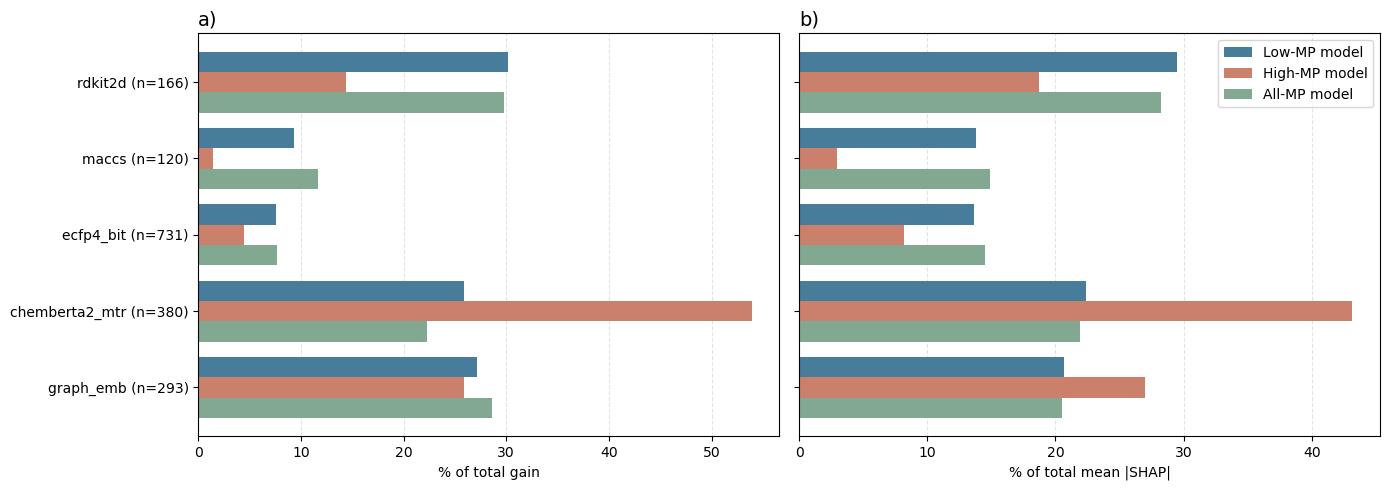

In [7]:
def plot_block_importance(figure_models, figsize=(14, 5)):
    """Gain (a) and SHAP (b) shares by representation block, one bar per model."""
    blocks = list(REPRESENTATION_PREFIXES)
    y = np.arange(len(blocks))
    bar_height = 0.8 / len(figure_models)
    fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=True)
    for panel, axis, column, xlabel in zip(['a)', 'b)'], axes, ['Gain_percent', 'SHAP_percent'],
                                            ['% of total gain', '% of total mean |SHAP|']):
        for offset, key in enumerate(figure_models):
            values = representation_importance.loc[representation_importance['Model'] == key].set_index('Block')[column].reindex(blocks)
            axis.barh(y + (offset - (len(figure_models) - 1) / 2) * bar_height, values, bar_height,
                      label=MODEL_LABELS[key], color=MODEL_COLORS[key])
        axis.set_xlabel(xlabel)
        axis.set_title(panel, loc='left', fontsize=14)
        axis.grid(axis='x', linestyle='--', alpha=0.35)
        axis.set_axisbelow(True)
    axes[0].set_yticks(y)
    axes[0].set_yticklabels([f'{block} (n={int((feature_blocks == block).sum())})' for block in blocks])
    axes[0].invert_yaxis()
    axes[1].legend()
    fig.tight_layout()
    return fig

fig = plot_block_importance(['L', 'H', 'All'])
# fig.savefig(FIGURE_DIR / 'representation_importance.png', dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

## Main figure: importance by representation block, full versus balanced-run models

The same block shares for the full Low-MP and All-MP models and their `balanced`-run counterparts: the undersampled Low-MP model (Low-MP (US)), trained on Low-MP compounds undersampled to the High-MP count (training and validation), and the balanced All-data model (BAL-MP), trained on those compounds plus all High-MP compounds. It shows whether the block profiles depend on the number of Low-MP training compounds and on the Low/High balance.

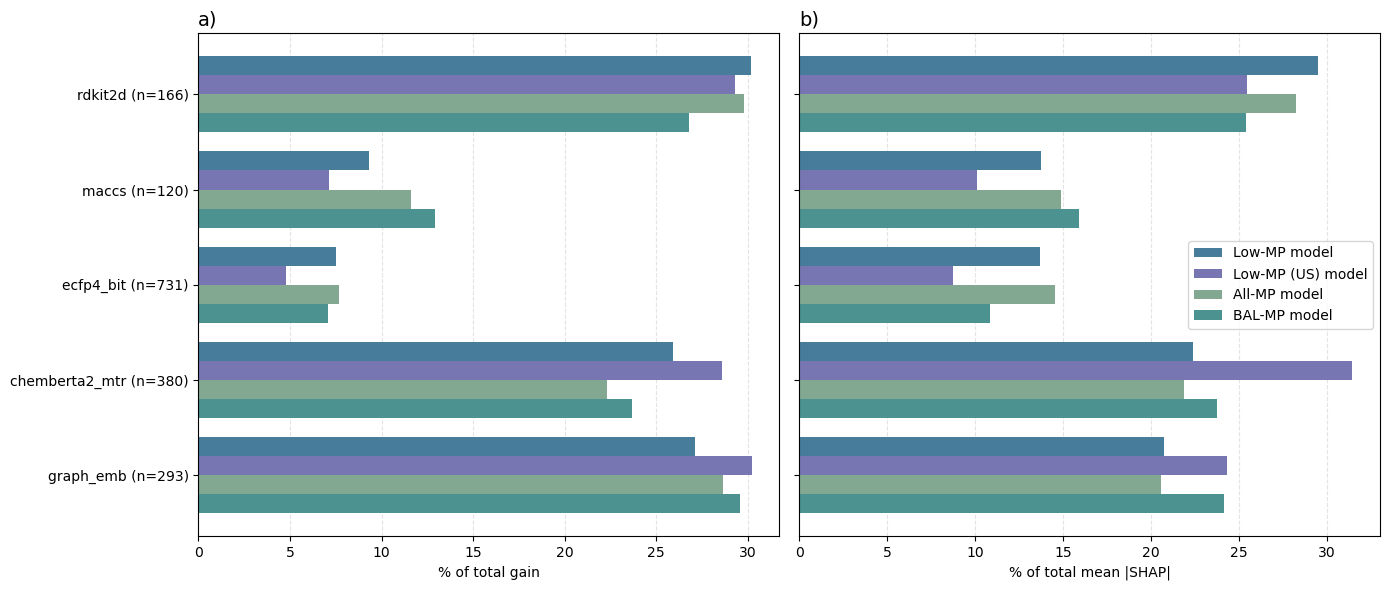

In [8]:
fig = plot_block_importance(['L', 'L_undersampled', 'All', 'All_balanced'], figsize=(14, 6))
# fig.savefig(FIGURE_DIR / 'representation_importance_full_vs_balanced.png', dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

## Main figure: SHAP beeswarm of the Low- and High-MP models

Top-20 features by mean |SHAP| for each model, on its own test subset. Colour is the feature value (red high, blue low). Both panels use the same x-range. Feature names in bold are in both top-20 lists.

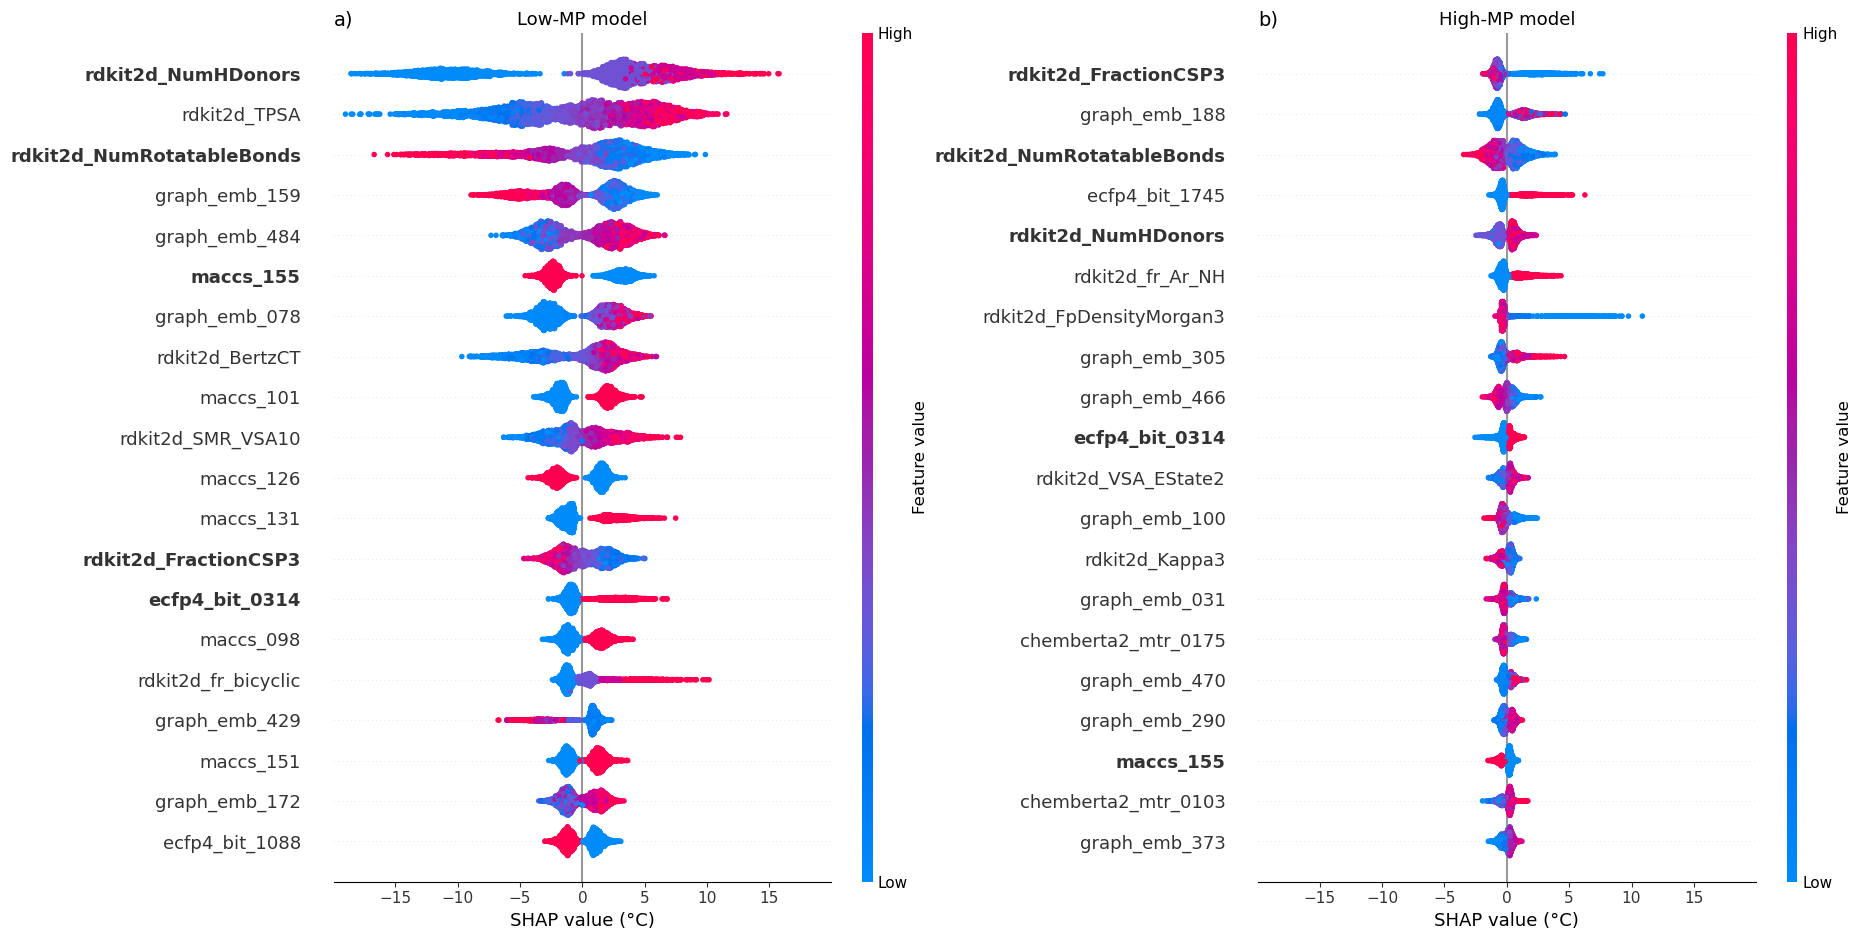

Shared top-20 features: ['ecfp4_bit_0314', 'maccs_155', 'rdkit2d_FractionCSP3', 'rdkit2d_NumHDonors', 'rdkit2d_NumRotatableBonds']


In [9]:
shared_top = set(top_features('L', TOP_N)) & set(top_features('H', TOP_N))
shap_xlim = max(float(np.abs(shap_explanations[key].values).max()) for key in ['L', 'H']) * 1.05
fig, axes = plt.subplots(1, 2, figsize=(19, 9.5))
for panel, ax, key in zip(['a)', 'b)'], axes, ['L', 'H']):
    beeswarm(ax, key, shared_top, shap_xlim)
    ax.set_title(panel, loc='left', fontsize=14)
#fig.suptitle(f'SHAP summary of the Low MP and High MP models (bold: in both top-{TOP_N} lists)', fontsize=14)
fig.tight_layout()
# fig.savefig(FIGURE_DIR / 'shap_beeswarm_L_H.png', dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()
print('Shared top-20 features:', sorted(shared_top))

## Main figure: top-10 SHAP features, Low- versus High-MP models

Bars are each feature's share of its model's total mean |SHAP|, so the two models are on a comparable scale.

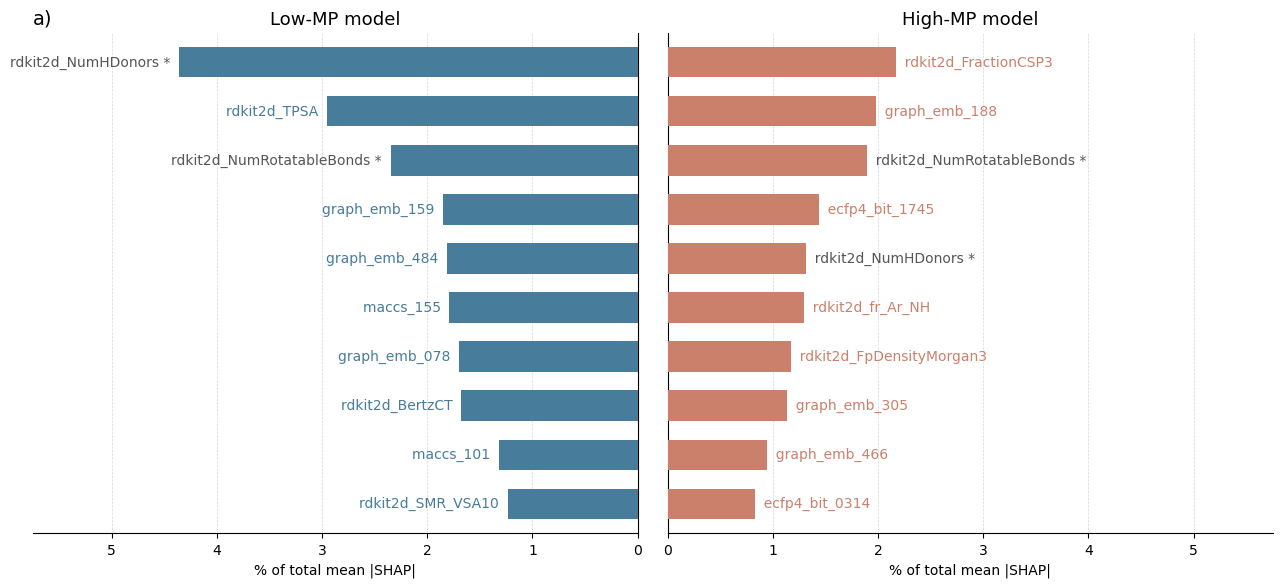

Shared top-10 features: ['rdkit2d_NumHDonors', 'rdkit2d_NumRotatableBonds']


In [10]:
fig, shared_L_H = mirrored_top10('L', 'H', 'Top-10 SHAP features: Low MP versus High MP models', panel_label='a)')
# fig.savefig(FIGURE_DIR / 'mirrored_top10_shap_L_vs_H.png', dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()
print('Shared top-10 features:', sorted(shared_L_H))

## Main figure: Low- versus High-MP values of the top features

The features are the union of the Low- and High-MP models' top-10 SHAP lists. Values come from the training set. Continuous features are shown as boxplots (whiskers at 1.5 IQR, outliers hidden, black dot = mean); binary MACCS and ECFP4 features as the percentage of compounds with the bit set. Title colour: blue = Low-MP top 10 only, red = High-MP top 10 only, grey with `*` = both.

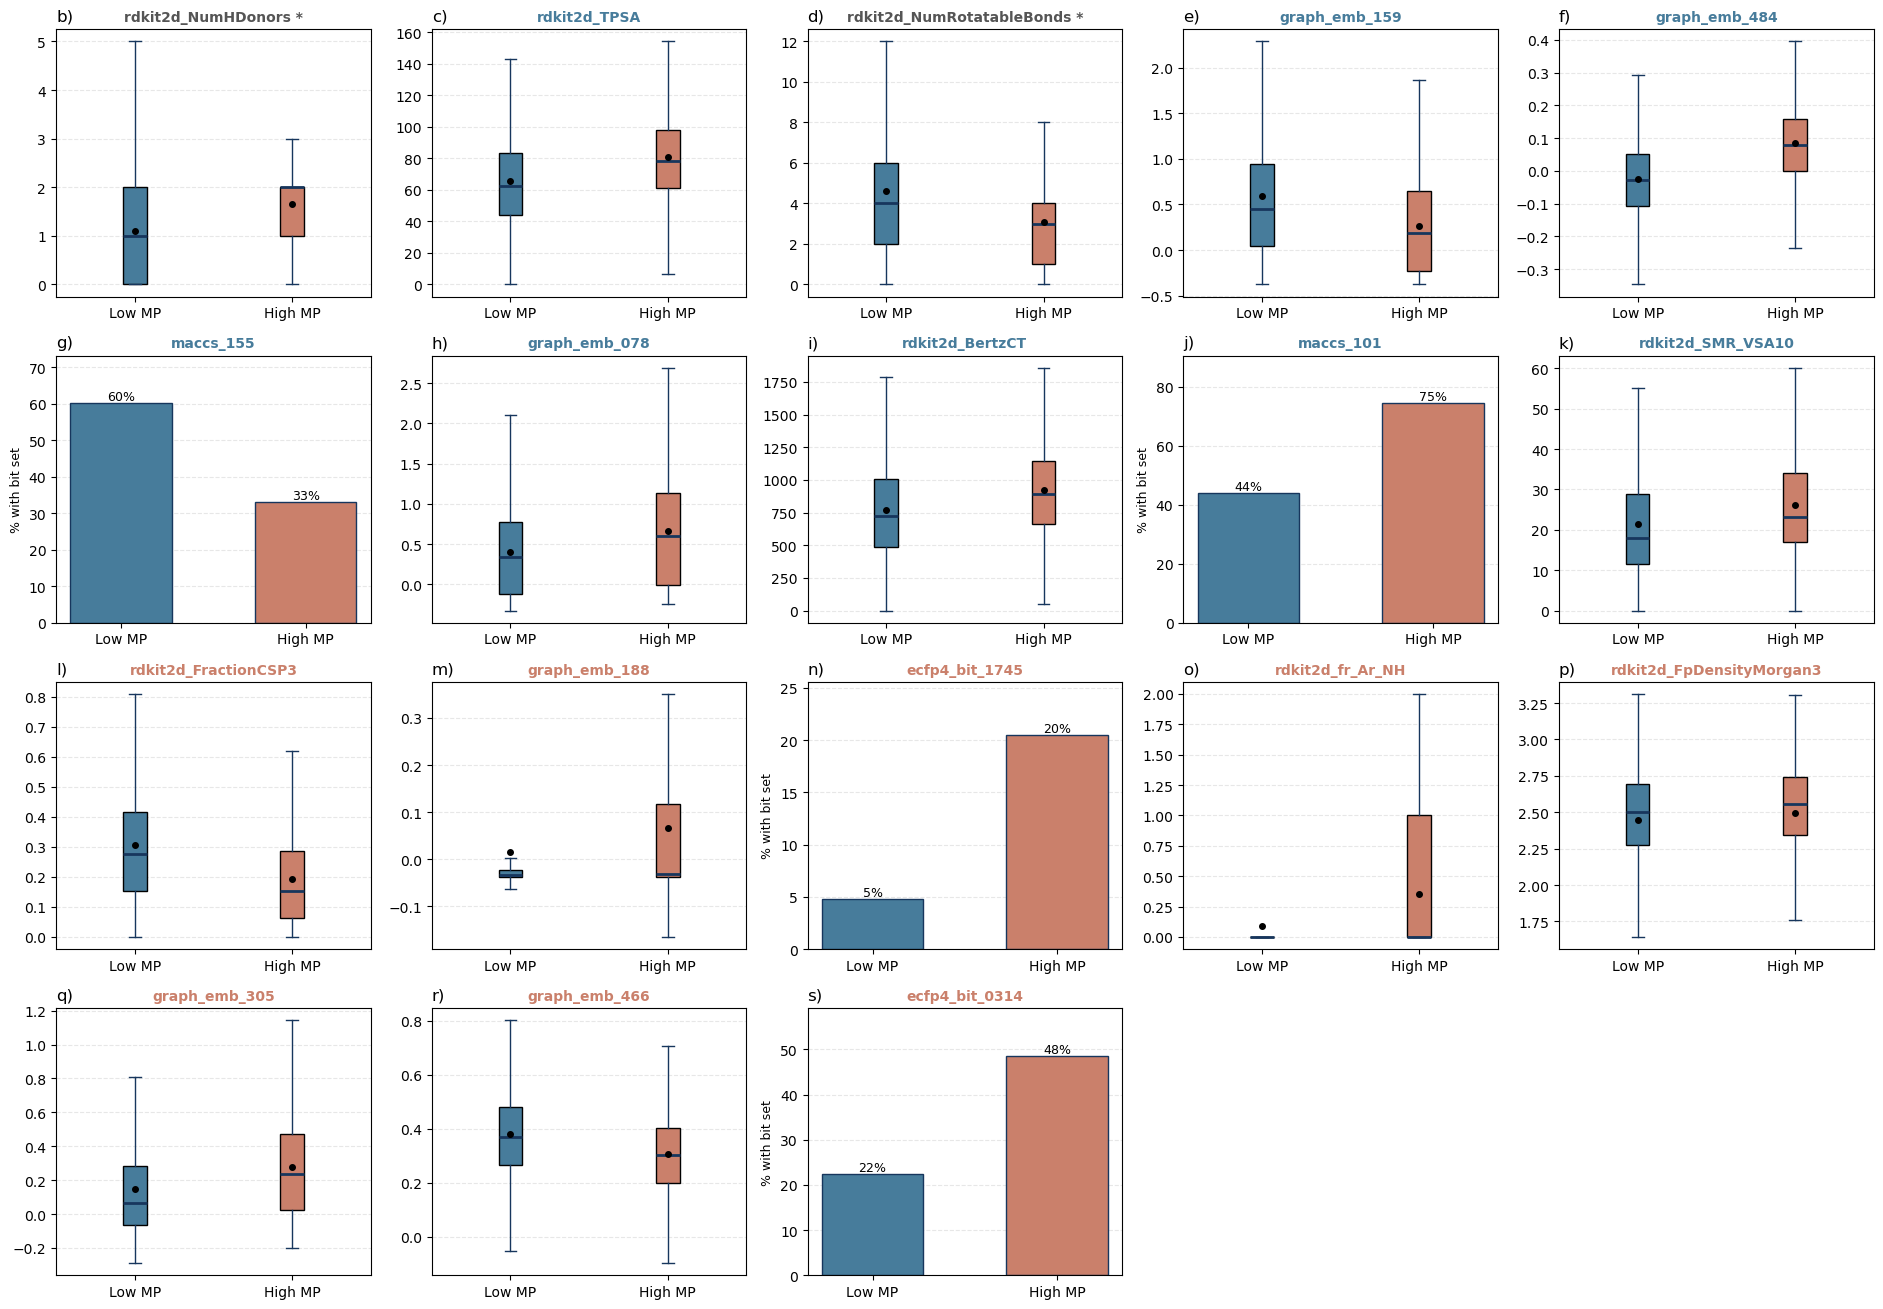

,Feature,Top10_of,Type,Low_N,High_N,Low_mean,High_mean,Low_median,High_median,Low_IQR,High_IQR
0,rdkit2d_NumHDonors,both,continuous,153434,12846,1.092,1.648,1.000,2.000,2.000,1.000
1,rdkit2d_TPSA,L,continuous,153434,12846,65.546,81.034,62.240,78.180,39.630,37.288
2,rdkit2d_NumRotatableBonds,both,continuous,153434,12846,4.604,3.059,4.000,3.000,4.000,3.000
3,graph_emb_159,L,continuous,153434,12846,0.592,0.259,0.455,0.186,0.898,0.872
4,graph_emb_484,L,continuous,153434,12846,-0.024,0.084,-0.028,0.078,0.160,0.158
5,maccs_155,L,binary,153434,12846,0.601,0.329,1.000,0.000,1.000,1.000
6,graph_emb_078,L,continuous,153434,12846,0.398,0.662,0.342,0.594,0.889,1.151
7,rdkit2d_BertzCT,L,continuous,153434,12846,770.713,919.031,722.448,891.244,522.298,478.884
8,maccs_101,L,binary,153434,12846,0.439,0.747,0.000,1.000,1.000,1.000
9,rdkit2d_SMR_VSA10,L,continuous,153434,12846,21.471,26.164,17.970,23.209,17.366,17.307


In [11]:
low_top10, high_top10 = top_features('L', 10), top_features('H', 10)
contrast_features = list(dict.fromkeys(low_top10 + high_top10))
train_values = pd.read_parquet(TRAIN_PATH, columns=[CLASS_COLUMN] + contrast_features)
train_labels = normalized_class(train_values)
low_rows = train_values.loc[train_labels.eq('low'), contrast_features].astype(float)
high_rows = train_values.loc[train_labels.eq('high'), contrast_features].astype(float)

def top10_membership(feature):
    if feature in low_top10 and feature in high_top10:
        return 'both'
    return 'L' if feature in low_top10 else 'H'

contrast_rows = []
for feature in contrast_features:
    low_values, high_values = low_rows[feature], high_rows[feature]
    contrast_rows.append({
        'Feature': feature,
        'Top10_of': top10_membership(feature),
        'Type': 'binary' if is_binary_feature(feature) else 'continuous',
        'Low_N': len(low_values),
        'High_N': len(high_values),
        'Low_mean': low_values.mean(),
        'High_mean': high_values.mean(),
        'Low_median': low_values.median(),
        'High_median': high_values.median(),
        'Low_IQR': low_values.quantile(0.75) - low_values.quantile(0.25),
        'High_IQR': high_values.quantile(0.75) - high_values.quantile(0.25),
    })
contrast_summary = pd.DataFrame(contrast_rows)
contrast_summary.to_csv(TABLE_DIR / 'feature_contrast_summary.csv', index=False)

title_colors = {'L': MODEL_COLORS['L'], 'H': MODEL_COLORS['H'], 'both': SHARED_COLOR}
n_columns = 5
n_rows = int(np.ceil(len(contrast_features) / n_columns))
fig, axes = plt.subplots(n_rows, n_columns, figsize=(19, n_rows * 3.3), squeeze=False)
axes = axes.ravel()
# Panels b), c), ... follow panel a), the mirrored top-10 figure.
for panel, axis, feature in zip('bcdefghijklmnopqrstuvwxyz', axes, contrast_features):
    low_values, high_values = low_rows[feature].to_numpy(), high_rows[feature].to_numpy()
    if is_binary_feature(feature):
        percents = [100 * low_values.mean(), 100 * high_values.mean()]
        bars = axis.bar(['Low MP', 'High MP'], percents, color=[LOW_BOX_COLOR, HIGH_BOX_COLOR], edgecolor='#17365D', width=0.55)
        for bar, value in zip(bars, percents):
            axis.text(bar.get_x() + bar.get_width() / 2, value, f'{value:.0f}%', ha='center', va='bottom', fontsize=9)
        axis.set_ylim(0, max(percents) * 1.2 + 1)
        axis.set_ylabel('% with bit set', fontsize=9)
    else:
        boxplot = axis.boxplot(
            [low_values, high_values],
            tick_labels=['Low MP', 'High MP'],
            patch_artist=True,
            showfliers=False,
            showmeans=True,
            meanprops={'marker': 'o', 'markerfacecolor': 'black', 'markeredgecolor': 'black', 'markersize': 4},
            medianprops={'color': '#17365D', 'linewidth': 2},
            whiskerprops={'color': '#17365D'},
            capprops={'color': '#17365D'},
        )
        boxplot['boxes'][0].set_facecolor(LOW_BOX_COLOR)
        boxplot['boxes'][1].set_facecolor(HIGH_BOX_COLOR)
    membership = top10_membership(feature)
    axis.set_title(f'{feature} *' if membership == 'both' else feature, fontsize=10, fontweight='bold', color=title_colors[membership])
    axis.set_title(f'{panel})', loc='left', fontsize=12)
    axis.grid(axis='y', linestyle='--', alpha=0.3)
    axis.set_axisbelow(True)
for axis in axes[len(contrast_features):]:
    axis.axis('off')
#fig.suptitle('Top-10 SHAP features of the Low MP and High MP models: values in Low MP versus High MP training compounds', fontsize=14, y=1.01)
fig.tight_layout()
# fig.savefig(FIGURE_DIR / 'feature_contrast_L_vs_H.png', dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()
display(contrast_summary.round(3))

## Supplementary figure: SHAP beeswarm of the All-data model

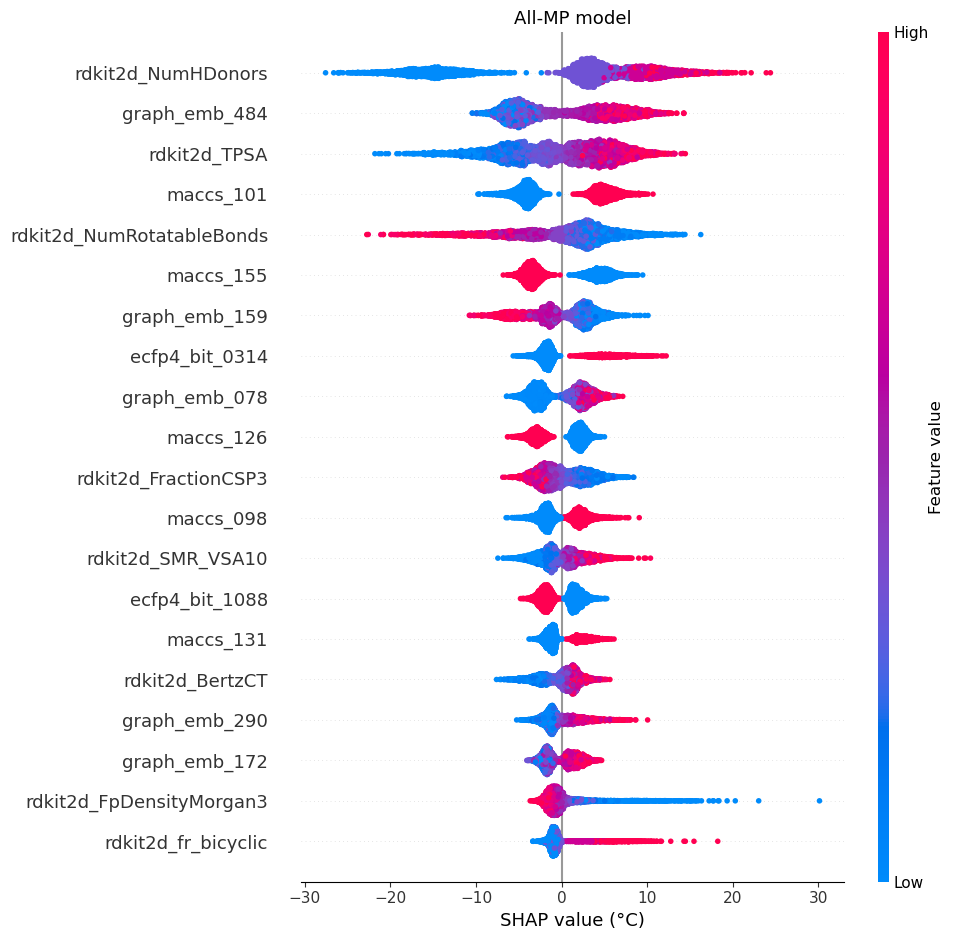

In [12]:
fig, ax = plt.subplots(figsize=(10, 9.5))
beeswarm(ax, 'All')
fig.tight_layout()
# fig.savefig(FIGURE_DIR / 'shap_beeswarm_All.png', dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

## Supplementary figure: gain importance

Top-20 features by gain for each model, as a share of the model's total gain.

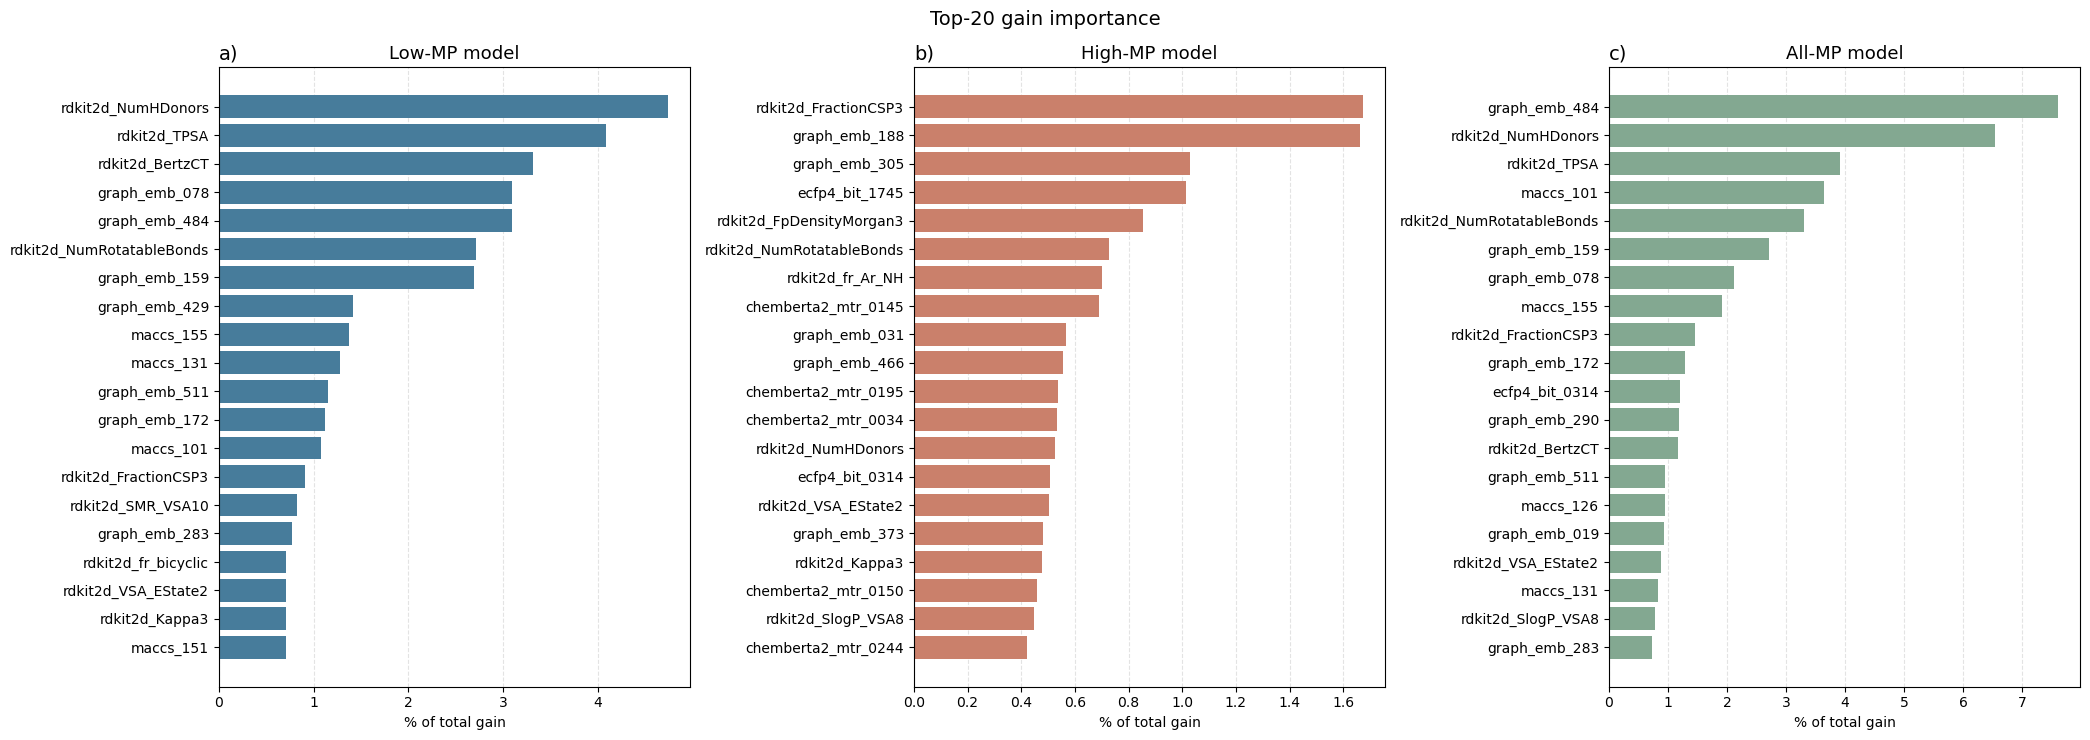

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(21, 7.5))
for panel, axis, key in zip(['a)', 'b)', 'c)'], axes, ['L', 'H', 'All']):
    top = importance_tables[key].head(TOP_N).iloc[::-1]
    axis.barh(top['Feature'], top['Gain_percent'], color=MODEL_COLORS[key])
    axis.set_xlabel('% of total gain')
    axis.set_title(MODEL_LABELS[key], color='black', fontsize=13)
    axis.set_title(panel, loc='left', fontsize=14)
    axis.grid(axis='x', linestyle='--', alpha=0.35)
    axis.set_axisbelow(True)
fig.suptitle(f'Top-{TOP_N} gain importance', fontsize=14)
fig.tight_layout()
# fig.savefig(FIGURE_DIR / 'gain_importance_L_H_All.png', dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

## Full versus undersampled Low-MP model

The undersampled Low-MP model was trained on a Low-MP training table undersampled to the High-MP training count; at the final refit the full Low-MP validation subset was added, as for every final model (row counts in the model table above). This section checks two things:

1. Does the Low-MP feature ranking change when the model is trained on far fewer Low-MP compounds?
2. Does the undersampled Low-MP model still differ from the High-MP model as much as the full Low-MP model does? If so, the Low/High difference in feature importance is not just an effect of training-set size.

Both Low-MP models are explained on the same Low-MP test sample.

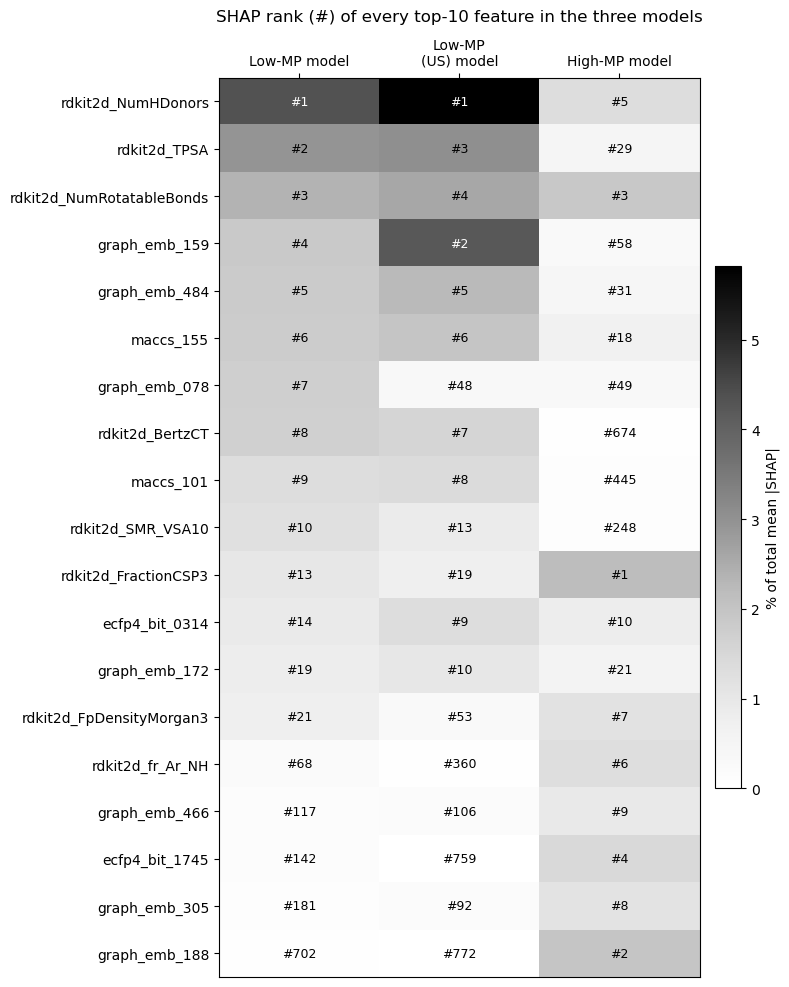

In [14]:
heatmap_keys = ['L', 'L_undersampled', 'H']
rank_lookup = {key: shap_tables[key].set_index('Feature')['SHAP_rank'] for key in heatmap_keys}
percent_lookup = {key: shap_tables[key].set_index('Feature')['SHAP_percent'] for key in heatmap_keys}
heat_features = list(dict.fromkeys(feature for key in heatmap_keys for feature in top_features(key, 10)))
heat_features = sorted(heat_features, key=lambda feature: rank_lookup['L'][feature])
heat_percent = pd.DataFrame({key: percent_lookup[key].reindex(heat_features) for key in heatmap_keys})
heat_rank = pd.DataFrame({key: rank_lookup[key].reindex(heat_features) for key in heatmap_keys})

fig, ax = plt.subplots(figsize=(8, 0.42 * len(heat_features) + 2))
vmax = float(heat_percent.to_numpy().max())
image = ax.imshow(heat_percent.to_numpy(), cmap='Greys', vmin=0, vmax=vmax, aspect='auto')
for row, feature in enumerate(heat_features):
    for column, key in enumerate(heatmap_keys):
        value = heat_percent.loc[feature, key]
        ax.text(column, row, f'#{int(heat_rank.loc[feature, key])}', ha='center', va='center', fontsize=9,
                color='white' if value > 0.55 * vmax else 'black')
ax.xaxis.tick_top()
ax.set_xticks(range(len(heatmap_keys)))
ax.set_xticklabels([MODEL_LABELS[key].replace(' (', '\n(') for key in heatmap_keys], fontsize=10)
for tick, key in zip(ax.xaxis.get_major_ticks(), heatmap_keys):
    tick.label2.set_color('black')
ax.set_yticks(range(len(heat_features)))
ax.set_yticklabels(heat_features, fontsize=10)
colorbar = fig.colorbar(image, ax=ax, fraction=0.05, pad=0.03)
colorbar.set_label('% of total mean |SHAP|')
ax.set_title('SHAP rank (#) of every top-10 feature in the three models', fontsize=12, pad=12)
fig.tight_layout()
# fig.savefig(FIGURE_DIR / 'shap_rank_heatmap_L_Lundersampled_H.png', dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

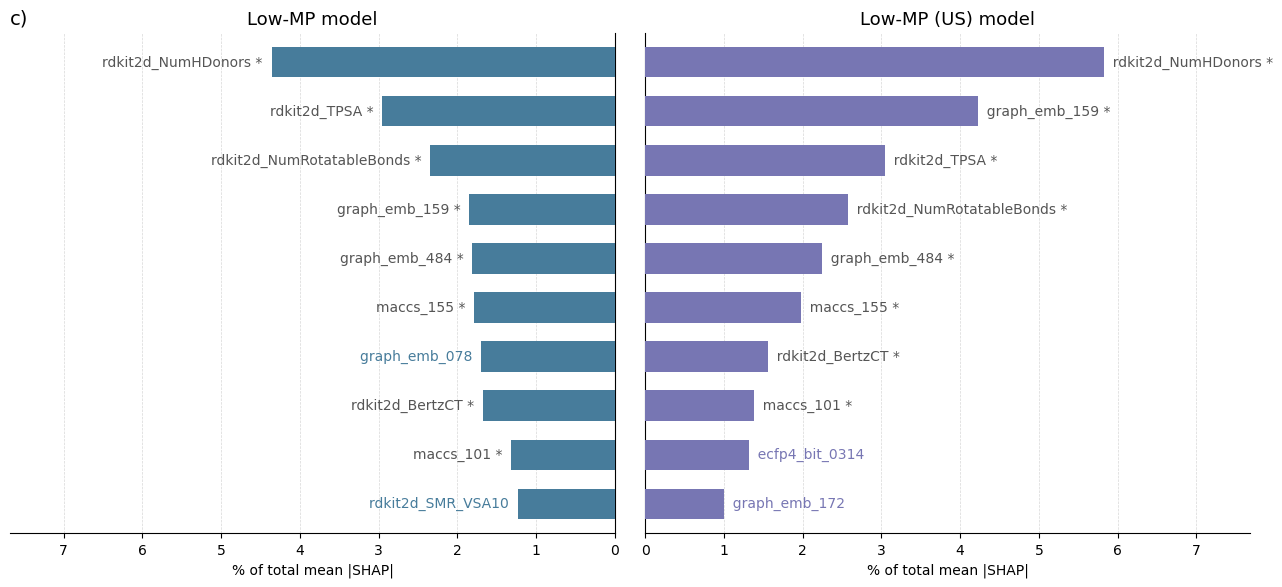

Shared top-10 features: ['graph_emb_159', 'graph_emb_484', 'maccs_101', 'maccs_155', 'rdkit2d_BertzCT', 'rdkit2d_NumHDonors', 'rdkit2d_NumRotatableBonds', 'rdkit2d_TPSA']


In [15]:
fig, shared_L_Lus = mirrored_top10('L', 'L_undersampled', 'Top-10 SHAP features: full versus undersampled Low MP models',  panel_label='c)')
# fig.savefig(FIGURE_DIR / 'mirrored_top10_shap_L_vs_L_undersampled.png', dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()
print('Shared top-10 features:', sorted(shared_L_Lus))

In [16]:
# Numbers to quote: top-N overlap for each model pair.
display(overlap_summary.drop(columns='Shared_features').round(2))

,Model_pair,Top_N,N_shared,Jaccard
0,L vs H,10,2,0.11
1,L vs H,20,5,0.14
2,L_undersampled vs H,10,3,0.18
3,L_undersampled vs H,20,6,0.18
4,L vs L_undersampled,10,8,0.67
5,L vs L_undersampled,20,15,0.60
